# Grupa B – Decision Tree

Sprawdźcie, jak liczba i jakość informacji wpływają na wynik drzewa oraz prześledźcie jedną przykładową decyzję. Notebook sam przygotowuje dane i pipeline.

`y = yes` oznacza założenie lokaty. `duration` jest wyłączone, bo przed rozmową nie jest znane.

In [ ]:
# Uruchom tę komórkę jako pierwszą – także po każdym restarcie środowiska wykonawczego.
# W Colabie pobiera (albo aktualizuje) repozytorium z GitHuba, lokalnie używa plików z dysku.
import subprocess
import sys
from pathlib import Path

PROJECT = "02_ml_bank_marketing_colab"

if "google.colab" in sys.modules:
    repo_dir = Path("/content/Podstawy_technologii_ML")
    if (repo_dir / ".git").exists():
        subprocess.run(["git", "-C", str(repo_dir), "pull", "--quiet"], check=True)
    else:
        repo_url = "https://github.com/poochacz/Podstawy_technologii_ML.git"
        subprocess.run(["git", "clone", "--quiet", repo_url, str(repo_dir)], check=True)
    ROOT = repo_dir / PROJECT
else:
    here = Path.cwd().resolve()
    ROOT = next(
        (path for folder in (here, *here.parents) for path in (folder, folder / PROJECT) if (path / "scripts").is_dir()),
        None,
    )
    if ROOT is None:
        raise FileNotFoundError(f"Nie znaleziono folderu {PROJECT}.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "data"
print("Środowisko gotowe:", ROOT)

In [2]:
from scripts.data_setup import prepare_model_data

N_RECORDS = 2000
RANDOM_STATE = 42
df, data_metadata = prepare_model_data(
    n=N_RECORDS,
    random_state=RANDOM_STATE,
    data_dir=DATA_DIR,
)
print(f"Dane gotowe: {df.shape[0]} rekordów, {df.shape[1] - 1} cech.")

Dane gotowe: 2000 rekordów, 9 cech.


In [3]:
from scripts.modeling import preprocess_data

df_for_modelling = preprocess_data(df)

## 1. Train/test split

Dzielimy 2000 klientów na 1600 do treningu i 400 do testu. Test jest zawsze ten sam, dzięki czemu możemy uczciwie porównywać modele.
Accuracy modelu naiwnego (który zawsze odpowiada „brak lokaty”) to 88,8%.

In [4]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 400
SPLIT_SEED = 42

# usuwamy y (czyli 'target') - dlaczego?
X = df_for_modelling.drop(columns="y")
y = df_for_modelling["y"]

# Tutaj budujemy dane do treningu i testy. X to cechy, a y to target - czyli wzięcie lub nie lokaty
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SPLIT_SEED,
    stratify=y,
)

print(f"Train: {len(X_train)} rekordów; test: {len(X_test)} rekordów.")

Train: 1600 rekordów; test: 400 rekordów.


In [6]:
# można zobaczyć jakie cechy są wykorzystywane przez model - wiele jest dodanych tylko na potrzeby trenowania modelu
X_train.columns.tolist()

['age',
 'campaign',
 'pdays',
 'had_previous_contact',
 'job_admin.',
 'job_blue-collar',
 'job_entrepreneur',
 'job_housemaid',
 'job_management',
 'job_retired',
 'job_self-employed',
 'job_services',
 'job_student',
 'job_technician',
 'job_unemployed',
 'job_unknown',
 'education_basic.4y',
 'education_basic.6y',
 'education_basic.9y',
 'education_high.school',
 'education_illiterate',
 'education_professional.course',
 'education_university.degree',
 'education_unknown',
 'housing_no',
 'housing_unknown',
 'housing_yes',
 'contact_cellular',
 'contact_telephone',
 'month_apr',
 'month_aug',
 'month_dec',
 'month_jul',
 'month_jun',
 'month_mar',
 'month_may',
 'month_nov',
 'month_oct',
 'month_sep']

## 2. Drzewo decyzyjne

Drzewo decyzyjne ma 2 najważniejsze cechy - max depth, czyli ile 'poziomów' ma drzewo (głebokość drzewo). Drzewo o głebokości 8 jest uznawane w prostszych datasetach za całkiem głębokie.
min_samples_leaf - jeśli w danym liściu drzewa mamy mniej niż 8 próbek, to dana gałąź nie jest już rozwijana i kończy się.
Zachęcamy do zmian tych zmiennych i sprawdzenia wpływu na wynik.

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Budujemy drzewo decyzyjne
tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=8, random_state=SPLIT_SEED)

# Uczymy drzewo na danych treningowych
tree.fit(X_train, y_train)

# Sprawdzamy drzewo na danych testowych
y_pred_tree = tree.predict(X_test)
print(f"Accuracy drzewa: {accuracy_score(y_test, y_pred_tree):.1%}")
print(f"Accuracy baseline (zawsze brak lokaty): {accuracy_score(y_test, ['no'] * len(y_test)):.1%}")

Accuracy drzewa: 87.5%
Accuracy baseline (zawsze brak lokaty): 88.8%


## 2a. Czy accuracy mówi wszystko?

Tylko ok. 11% klientów zakłada lokatę. Sprawdźmy, ilu z nich drzewo faktycznie znalazło.
**Recall dla `yes`** = jaki procent chętnych model poprawnie wskazał.
Metryki będą dokładniej opisane na kolejnym wykładzie, ale zwróćcie uwagę na macierz błędów. Model 'baseline' zawsze wskazuje 'no'. Nasz model ma niecogorszy wynik, ale udaje mu się w kilku przypadkach wskazać poprawnie, że ktoś weźmie lokatę. 

In [13]:
import pandas as pd
from sklearn.metrics import recall_score

recall_yes = recall_score(y_test, y_pred_tree, pos_label="yes")
print(f"Recall dla 'yes': {recall_yes:.1%}")

# Tablica pomyłek: wiersze = prawda, kolumny = co przewidziało drzewo
pd.crosstab(y_test, y_pred_tree, rownames=["naprawdę"], colnames=["przewidziane"])

Recall dla 'yes': 8.9%


przewidziane,no,yes
naprawdę,,
no,346,9
yes,41,4


## 2b. Drzewo, które bardziej dba o klientów `yes`

`class_weight="balanced"` każe drzewu traktować obie klasy jako równie ważne, mimo że `yes` jest dużo rzadsze. Co robi class_weight=balanced - nie jest istotne. Zapamiętajcie raczej, że ten sam algorytm może mieć podobną jakość ogólną (accuracy) ale inaczej rozłożoną - może trafiać więcej klientów na 'tak', lub więcej na 'nie'. 

**Balanced accuracy** = średnia z trafności osobno dla `no` i osobno dla `yes`. Model, który zawsze mówi „nie”, dostaje tu tylko 50%, czyli tyle, co rzut monetą.

In [15]:
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score

tree_balanced = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=SPLIT_SEED,
)
tree_balanced.fit(X_train, y_train)
y_pred_balanced = tree_balanced.predict(X_test)

predictions = {
    "baseline (zawsze brak lokaty)": ["no"] * len(y_test),
    "zwykłe drzewo": y_pred_tree,
    "drzewo balanced": y_pred_balanced,
}
comparison = pd.DataFrame(
    {
        "accuracy": [accuracy_score(y_test, pred) for pred in predictions.values()],
        "balanced_accuracy": [balanced_accuracy_score(y_test, pred) for pred in predictions.values()],
        "recall_yes": [recall_score(y_test, pred, pos_label="yes") for pred in predictions.values()],
    },
    index=predictions.keys(),
)
display(comparison.round(3))

print("Macierz pomyłek dla drzewa balanced:")
pd.crosstab(y_test, y_pred_balanced, rownames=["naprawdę"], colnames=["przewidziane"])

,accuracy,balanced_accuracy,recall_yes
baseline (zawsze brak lokaty),0.888,0.500,0.000
zwykłe drzewo,0.875,0.532,0.089
drzewo balanced,0.635,0.610,0.578


Macierz pomyłek dla drzewa balanced:


przewidziane,no,yes
naprawdę,,
no,228,127
yes,19,26


## 3. Jak drzewo podejmuje decyzję?

Poniższy wykres pokazuje zwykłe drzewo z sekcji 2 (pierwsze 3 poziomy). Każdy węzeł zadaje jedno pytanie o cechę klienta: jeśli warunek jest spełniony, idziemy w lewo (True), jeśli nie, w prawo (False). Wybierzcie klienta ze zbioru testowego (np. `X_test.iloc[0]`) i prześledźcie na wykresie jego drogę od góry do liścia.

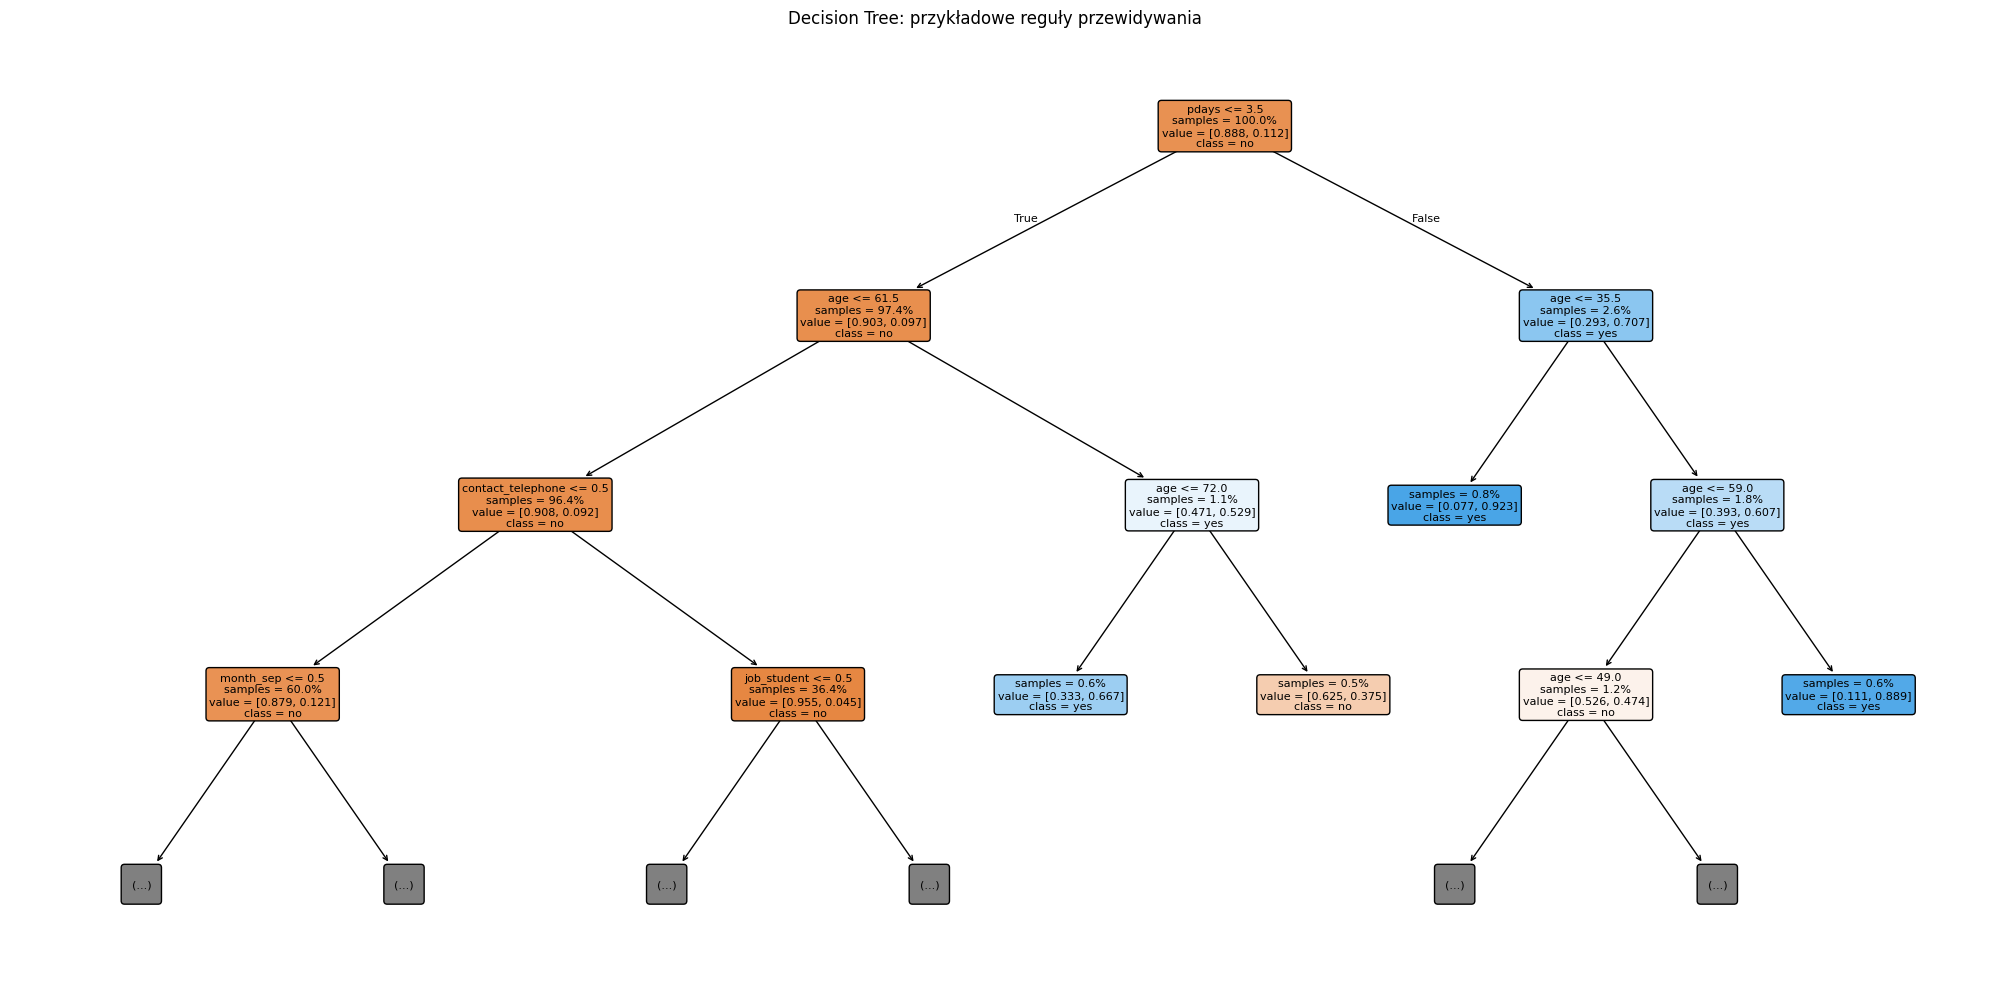

In [16]:
from scripts.explainability import plot_decision_tree

plot_decision_tree(tree, max_depth=3)

## 4. Więcej danych: cały zbiór

Do tej pory pracowaliśmy na 2000 klientach. Teraz wczytujemy **cały zbiór (ponad 41 tys. klientów)** i dzielimy go na trening (80%) i test (20%, ponad 8 tys. klientów). Tak duży test daje dużo stabilniejsze wyniki.

Od tego miejsca używamy drzewa `balanced` z sekcji 2b. Wyniki nie są wprost porównywalne z sekcjami 1–3, bo zbiór testowy jest inny.

In [18]:
df_full, _ = prepare_model_data(n=None, random_state=RANDOM_STATE, data_dir=DATA_DIR)
df_full_for_modelling = preprocess_data(df_full)

X_full = df_full_for_modelling.drop(columns="y")
y_full = df_full_for_modelling["y"]

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=SPLIT_SEED,
    stratify=y_full,
)

print(f"Train: {len(X_train_full)} rekordów; test: {len(X_test_full)} rekordów.")

Train: 32950 rekordów; test: 8238 rekordów.


### 4a. Ile danych potrzebuje drzewo?

Zmieniajcie `TRAIN_SIZE` (np. 200, 1600, 5000, 32950) i obserwujcie wyniki. Zbiór testowy cały czas jest ten sam.

In [20]:
from sklearn.metrics import balanced_accuracy_score

# Zmień TRAIN_SIZE: od 100 do 32950 (cały zbiór treningowy)
TRAIN_SIZE = 10000

tree_full = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=SPLIT_SEED,
)

# Bierzemy pierwsze TRAIN_SIZE rekordów treningowych (train_test_split już je wymieszał)
tree_full.fit(X_train_full.iloc[:TRAIN_SIZE], y_train_full.iloc[:TRAIN_SIZE])

y_pred_full = tree_full.predict(X_test_full)
print(f"Trening na {TRAIN_SIZE} rekordach")
print(f"Accuracy: {accuracy_score(y_test_full, y_pred_full):.1%}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_full, y_pred_full):.1%}")

Trening na 10000 rekordach
Accuracy: 86.6%
Balanced accuracy: 68.2%


### 4b. Krzywa uczenia

Jeden trening to trochę loteria: inna próbka 200 klientów da inny wynik. Dlatego dla każdej wielkości zbioru treningowego (100, 300, 1 000, 3 000, 10 000) uczymy drzewo **10 razy** na różnych losowych próbkach, a na koniec raz na całym zbiorze treningowym, czyli razem 51 treningów. Może to potrwać kilkanaście sekund.

Na wykresie linia pokazuje średni wynik, a pas pokazuje najgorszy i najlepszy z 10 treningów.

**Uwaga:** dla całego zbioru treningowego (32 950) pasa nie ma, bo trening odbywa się tylko raz. Każde losowanie wybrałoby tych samych klientów, więc 10 treningów dałoby 10 identycznych wyników. To nie znaczy, że model jest wtedy idealnie stabilny: z innymi klientami w tej samej liczbie wynik też byłby trochę inny.

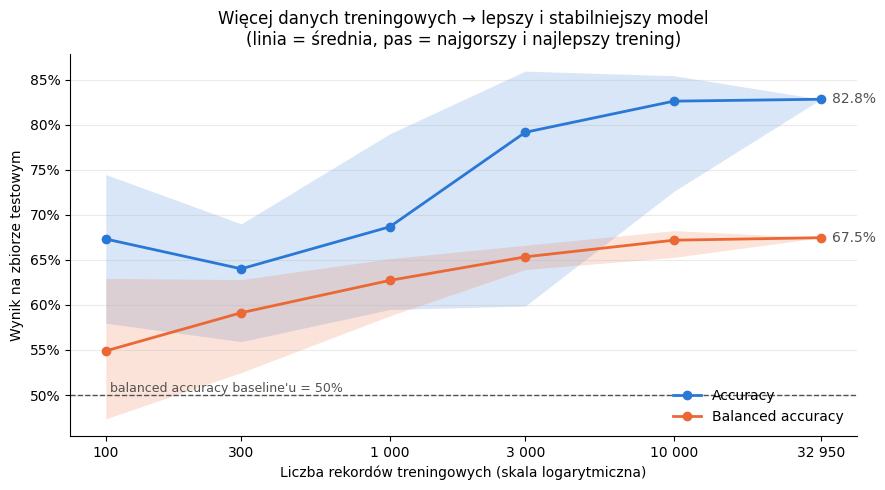

,accuracy_mean,accuracy_min,accuracy_max,balanced_accuracy_mean,balanced_accuracy_min,balanced_accuracy_max
train_size,,,,,,
100,0.673,0.580,0.745,0.549,0.474,0.629
300,0.640,0.559,0.690,0.591,0.525,0.628
1000,0.687,0.595,0.790,0.627,0.588,0.651
3000,0.791,0.599,0.859,0.653,0.639,0.666
10000,0.826,0.726,0.854,0.672,0.653,0.682
32950,0.828,0.828,0.828,0.675,0.675,0.675


In [21]:
from scripts.modeling import run_learning_curve, plot_learning_curve

learning_curve = run_learning_curve(
    DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=8,
        class_weight="balanced",
        random_state=SPLIT_SEED,
    ),
    X_train_full,
    y_train_full,
    X_test_full,
    y_test_full,
)
plot_learning_curve(learning_curve)

## 5. Które cechy są ważne?

Wpiszcie do `FEATURES_TO_DROP` cechy, które chcecie usunąć, np. `["month"]` albo `["pdays", "had_previous_contact"]`. Drzewo uczy się na całym zbiorze treningowym dwa razy: ze wszystkimi cechami i bez wybranych.

Dostępne cechy: `age`, `job`, `education`, `housing`, `contact`, `month`, `campaign`, `pdays`, `had_previous_contact`.

In [ ]:
from scripts.modeling import drop_features

# Wpisz cechy do usunięcia po przecinku i w cudzysłowie(u?), np. ["month", "age"]
FEATURES_TO_DROP = ["month"]

X_train_dropped = drop_features(X_train_full, FEATURES_TO_DROP)
X_test_dropped = drop_features(X_test_full, FEATURES_TO_DROP)

# trenujemy jeszcze raz pełne drzewo
tree_all = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=SPLIT_SEED,
)
tree_all.fit(X_train_full, y_train_full)
y_pred_all = tree_all.predict(X_test_full)

# trenujemy drzewo bez wskzanych cech
tree_dropped = DecisionTreeClassifier(
    max_depth=8,
    min_samples_leaf=8,
    class_weight="balanced",
    random_state=SPLIT_SEED,
)
tree_dropped.fit(X_train_dropped, y_train_full)
y_pred_dropped = tree_dropped.predict(X_test_dropped)

pd.DataFrame(
    {
        "accuracy": [
            accuracy_score(y_test_full, y_pred_all),
            accuracy_score(y_test_full, y_pred_dropped),
        ],
        "balanced_accuracy": [
            balanced_accuracy_score(y_test_full, y_pred_all),
            balanced_accuracy_score(y_test_full, y_pred_dropped),
        ],
    },
    index=["wszystkie cechy", f"bez: {', '.join(FEATURES_TO_DROP)}"],
).round(3)

## Pytania do dyskusji

1. Jak accuracy drzewa wypada wobec baseline'u „zawsze brak lokaty”? A balanced accuracy?
2. Drzewo `balanced` ma niższą accuracy, ale wyższy recall. Który model wybrałby bank i dlaczego?
3. Jakie pytania zadało drzewo wybranemu klientowi, zanim dotarło do liścia? Do jakiego liścia trafił?
4. Jak zmieniają się wynik i rozrzut na krzywej uczenia, gdy rośnie liczba danych treningowych?
5. Usunięcie których cech najbardziej obniża wynik? Czy są cechy, których usunięcie prawie nic nie zmienia? Dlaczego tak może być?